In [1]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import find_peaks


def cargar_barrido(carpeta, exclude_bins=5):
    archivos = sorted(carpeta.glob("sweep_f_test_*.csv"))
    filas = []
    for archivo in archivos:
        m = re.search(r"sweep_f_test_([\d.]+)kHz", archivo.name)
        f_test = float(m.group(1)) * 1e3

        df = pd.read_csv(archivo)
        freq = df["Frequency"].to_numpy()
        amp = df["Amplitude"].to_numpy()

        # np.argmax(amp) a veces agarra el borde de la ventana (f_start) en
        # vez del tono inyectado: cuando f_test es chico, el span minimo del
        # SA fuerza f_start cerca de 1 Hz, y ahi hay una fuga/artefacto que
        # puede ser mas fuerte que el tono real. find_peaks exige un maximo
        # local (vecino de los dos lados), asi que no cuenta el borde.
        picos, _ = find_peaks(amp)
        i = picos[np.argmax(amp[picos])] if len(picos) > 0 else int(np.argmax(amp))

        # piso de ruido: mediana de la traza lejos del pico (si no, el tono
        # contamina la mediana), para poder calcular el SNR de cada punto
        mask = np.ones(len(amp), dtype=bool)
        lo, hi = max(0, i - exclude_bins), min(len(amp), i + exclude_bins + 1)
        mask[lo:hi] = False
        noise_floor = np.median(amp[mask])

        filas.append({
            "f_test": f_test,
            "peak_freq": freq[i],
            "peak_amp": amp[i],
            "noise_floor_dbm": noise_floor,
            "snr_db": amp[i] - noise_floor,
        })

    return pd.DataFrame(filas).sort_values("f_test").reset_index(drop=True)

## Calibracion (sin filtro)

In [ ]:
carpeta_calibracion = Path("../barridos/3/meseta")

resultados_calibracion = cargar_barrido(carpeta_calibracion)
print(f"{len(resultados_calibracion)} puntos en {carpeta_calibracion.name}")
resultados_calibracion.head()

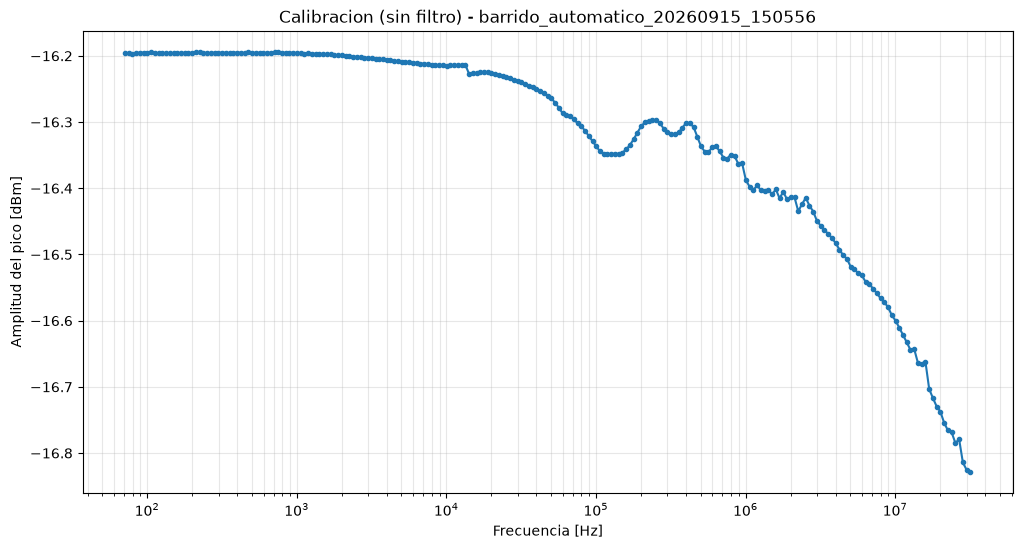

Amplitud media: -16.33 dBm
Desvio estandar: 0.16 dB
Rango pico a pico: 0.63 dB

Puntos por decada:
10^1 - 10^2 Hz     6
10^2 - 10^3 Hz    40
10^3 - 10^4 Hz    40
10^4 - 10^5 Hz    40
10^5 - 10^6 Hz    40
10^6 - 10^7 Hz    40
10^7 - 10^8 Hz    21
Name: count, dtype: int64


In [3]:
plt.figure(figsize=(12, 6))
plt.plot(resultados_calibracion["f_test"], resultados_calibracion["peak_amp"], "o-", ms=3)
plt.xscale("log")
plt.xlabel("Frecuencia [Hz]")
plt.ylabel("Amplitud del pico [dBm]")
plt.title(f"Calibracion (sin filtro) - {carpeta_calibracion.name}")
plt.grid(True, which="both", alpha=0.3)
plt.show()

print(f"Amplitud media: {resultados_calibracion['peak_amp'].mean():.2f} dBm")
print(f"Desvio estandar: {resultados_calibracion['peak_amp'].std():.2f} dB")
print(f"Rango pico a pico: {resultados_calibracion['peak_amp'].max() - resultados_calibracion['peak_amp'].min():.2f} dB")

# puntos por decada (decada = potencia de 10 en la que cae f_test)
decada = np.floor(np.log10(resultados_calibracion["f_test"])).astype(int)
puntos_por_decada = decada.value_counts().sort_index()
puntos_por_decada.index = [f"10^{d} - 10^{d+1} Hz" for d in puntos_por_decada.index]
print("\nPuntos por decada:")
print(puntos_por_decada)

## Con filtro (SLP-5+, f_c nominal = 6 MHz)

Completar `carpeta_filtro` con el barrido nuevo, ya con el filtro conectado.

f_c es donde la senal cae a la mitad de la potencia (-3 dB). Se calcula de
dos formas: comparando cada punto contra la meseta del propio barrido con
filtro (mas abajo), y comparando contra `resultados_calibracion` (mas abajo
aun, en "Atenuacion normalizada con la calibracion") -- ojo que esta ultima
puede ser de otra sesion/otro dia que el barrido con filtro (revisar fechas
de las carpetas), asi que sirve como comparacion pero no reemplaza medir
calibracion y filtro en la misma sesion cuando se pueda.

Nota: el modelo se llama "SLP-5+" pero el -3dB nominal del datasheet de
Mini-Circuits es 6 MHz, no 5 MHz -- el "5" en el nombre es el borde de la
banda de paso (perdida <1dB en DC-5MHz), no el punto de -3dB.

In [4]:
carpeta_filtro = Path("../barridos/3/barrido_automatico_3")
f_corte_hz = 6e6  # -3dB nominal del datasheet SLP-5+ (no 5 MHz, ver nota arriba)

resultados_filtro = cargar_barrido(carpeta_filtro)
if len(resultados_filtro) == 0:
    raise FileNotFoundError(f"No hay archivos sweep_f_test_*.csv en {carpeta_filtro} -- completar carpeta_filtro con el barrido nuevo.")
print(f"{len(resultados_filtro)} puntos en {carpeta_filtro.name}")
resultados_filtro.head()

558 puntos en barrido_automatico_3


,f_test,peak_freq,peak_amp,noise_floor_dbm,snr_db
0,67.00,67.00,-15.577731,-97.867992,82.290261
1,68.56,68.50,-15.578163,-93.921150,78.342987
2,70.16,70.15,-15.579358,-94.291248,78.711890
3,71.79,71.80,-15.579051,-96.381062,80.802011
4,73.47,73.45,-15.579234,-96.196607,80.617373


In [ ]:
# banda pasante de referencia: promedio de amplitud en frecuencias bajas (una
# decada por debajo del corte nominal), donde el filtro todavia no atenua.
# OJO: esto NO es la carpeta de calibracion "meseta" -- es la zona plana
# del propio barrido con filtro, una referencia alternativa que no depende
# de resultados_calibracion (ver seccion "Atenuacion normalizada" mas abajo
# para la version que si usa la calibracion real).
en_banda_pasante = resultados_filtro["f_test"] < f_corte_hz / 10
amp_banda_pasante = resultados_filtro.loc[en_banda_pasante, "peak_amp"].mean()

resultados_filtro["atenuacion_db"] = amp_banda_pasante - resultados_filtro["peak_amp"]

# f_c medida: frecuencia donde la atenuacion cruza 3 dB (mitad de potencia),
# interpolando en escala log de frecuencia. Aproximado -- asume que la
# atenuacion crece mas o menos monotona cerca del corte.
log_f = np.log10(resultados_filtro["f_test"])
f_corte_medida = 10 ** np.interp(3, resultados_filtro["atenuacion_db"], log_f)

print(f"Amplitud de banda pasante (referencia, f < f_c/10): {amp_banda_pasante:.2f} dBm")
print(f"f_c medida (3 dB de atenuacion): {f_corte_medida/1e6:.3f} MHz (nominal: {f_corte_hz/1e6:.3g} MHz)")

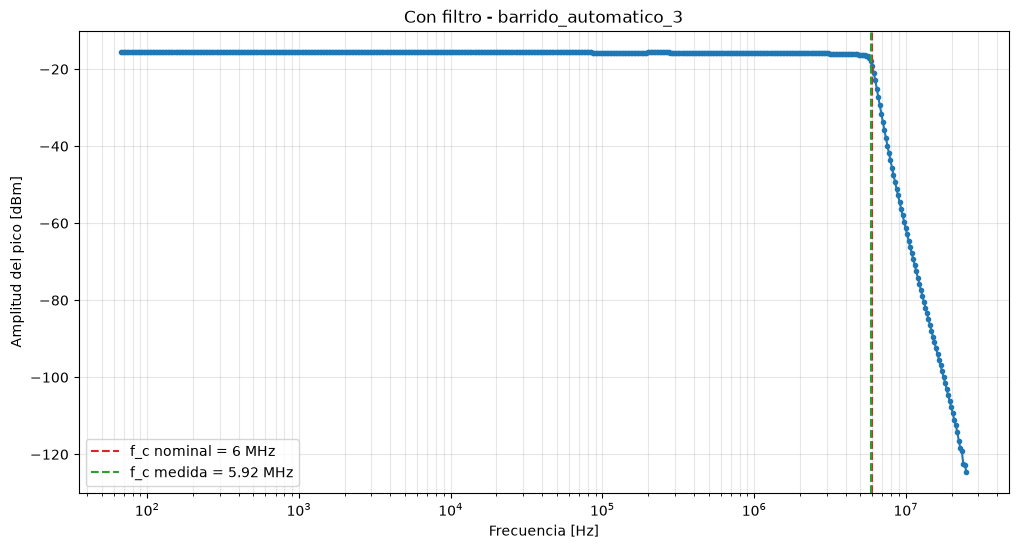

In [6]:
plt.figure(figsize=(12, 6))
plt.plot(resultados_filtro["f_test"], resultados_filtro["peak_amp"], "o-", ms=3)
plt.axvline(f_corte_hz, color="tab:red", linestyle="--", label=f"f_c nominal = {f_corte_hz/1e6:.3g} MHz")
plt.axvline(f_corte_medida, color="tab:green", linestyle="--", label=f"f_c medida = {f_corte_medida/1e6:.3g} MHz")
plt.xscale("log")
plt.xlabel("Frecuencia [Hz]")
plt.ylabel("Amplitud del pico [dBm]")
plt.title(f"Con filtro - {carpeta_filtro.name}")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.show()

Atenuacion respecto a la banda pasante propia del filtro (calculada en la
celda de arriba -- la zona plana de frecuencias bajas del propio barrido con
filtro, no la carpeta de calibracion), con las dos frecuencias de corte
marcadas: la nominal (5 MHz) y la medida (donde la atenuacion cruza 3 dB, o
sea mitad de potencia).

In [ ]:
plt.figure(figsize=(12, 6))
plt.plot(resultados_filtro["f_test"], resultados_filtro["atenuacion_db"], "o-", ms=3)
plt.axvline(f_corte_hz, color="tab:red", linestyle="--", label=f"f_c nominal = {f_corte_hz/1e6:.3g} MHz")
plt.axvline(f_corte_medida, color="tab:green", linestyle="--", label=f"f_c medida = {f_corte_medida/1e6:.3g} MHz")
plt.axhline(3, color="gray", linestyle=":", label="3 dB (mitad de potencia)")
plt.xscale("log")
plt.xlabel("Frecuencia [Hz]")
plt.ylabel("Atenuacion respecto a la banda pasante [dB]")
plt.title("Respuesta del filtro")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.show()

## Atenuacion normalizada con la calibracion (sin filtro)

La atenuacion de arriba se calculo contra la banda pasante propia del
barrido con filtro (promedio en frecuencias bajas), asumiendo que ahi la
respuesta de la cadena generador+cables+SA es plana. Pero
`resultados_calibracion` (la carpeta `meseta`, barrido loopback sin filtro,
ver seccion "Calibracion" y memoria `labo67-barridos-sin-filtro`) muestra
que esa cadena tiene ripple (~1-1.5 dB) y no es perfectamente plana en todo
el rango.

Aca se normaliza distinto: en cada `f_test` del barrido con filtro, se resta
la amplitud medida *sin* filtro a esa misma frecuencia (interpolando la
calibracion en escala log de frecuencia, porque los `f_test` de los dos
barridos no caen exactamente en los mismos puntos). Esa diferencia aisla la
respuesta propia del filtro, corrigiendo el ripple de la cadena de medicion en
vez de asumir que es plana.

In [ ]:
log_f_calibracion = np.log10(resultados_calibracion["f_test"])
log_f_filtro = np.log10(resultados_filtro["f_test"])

# interpolacion en escala log de frecuencia (np.interp necesita x creciente,
# por eso se ordena por f_test al cargar el barrido en cargar_barrido)
amp_calibracion_interp = np.interp(
    log_f_filtro, log_f_calibracion, resultados_calibracion["peak_amp"]
)
resultados_filtro["atenuacion_db_norm"] = amp_calibracion_interp - resultados_filtro["peak_amp"]

# misma serie que atenuacion_db_norm pero con el signo pensado como amplitud:
# 0 dB = igual que sin filtro (loopback), negativo = atenuado por el filtro.
# Es la amplitud del pico ya normalizada por la respuesta de la cadena de
# medicion (generador+cables+SA), no la amplitud absoluta en dBm.
resultados_filtro["peak_amp_norm_db"] = resultados_filtro["peak_amp"] - amp_calibracion_interp

# misma idea que f_corte_medida (celda de la meseta propia), pero con la
# atenuacion normalizada por calibracion
f_corte_medida_norm = 10 ** np.interp(3, resultados_filtro["atenuacion_db_norm"], log_f_filtro)

print(f"f_c medida (normalizada con calibracion): {f_corte_medida_norm/1e6:.3f} MHz "
      f"(nominal: {f_corte_hz/1e6:.3g} MHz)")
print(f"f_c medida (meseta propia, para comparar): {f_corte_medida/1e6:.3f} MHz")

In [ ]:
plt.figure(figsize=(12, 6))
plt.plot(resultados_filtro["f_test"], resultados_filtro["atenuacion_db"], "o-", ms=3,
         label="respecto a banda pasante propia")
plt.plot(resultados_filtro["f_test"], resultados_filtro["atenuacion_db_norm"], "o-", ms=3,
         label="respecto a calibracion (carpeta meseta, sin filtro)")
plt.axvline(f_corte_hz, color="tab:red", linestyle="--", label=f"f_c nominal = {f_corte_hz/1e6:.3g} MHz")
plt.axvline(f_corte_medida_norm, color="tab:green", linestyle="--",
            label=f"f_c medida (norm) = {f_corte_medida_norm/1e6:.3g} MHz")
plt.axhline(3, color="gray", linestyle=":", label="3 dB (mitad de potencia)")
plt.xscale("log")
plt.xlabel("Frecuencia [Hz]")
plt.ylabel("Atenuacion [dB]")
plt.title("Atenuacion: banda pasante propia vs. normalizada con calibracion")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.show()

diferencia = (resultados_filtro["atenuacion_db_norm"] - resultados_filtro["atenuacion_db"]).abs()
print(f"Diferencia entre los dos metodos: media={diferencia.mean():.3f} dB, "
      f"maxima={diferencia.max():.3f} dB")

### Amplitud del pico, normalizada

El grafico "Con filtro" de mas arriba (`peak_amp` en dBm crudo) mezcla la
respuesta del filtro con la respuesta propia de la cadena generador+cables+SA
(la que se ve en "Calibracion"). Aca se resta esa referencia punto a punto
(`peak_amp_norm_db = peak_amp - calibracion interpolada`), asi que 0 dB
significa "igual que sin filtro" y lo que cae por debajo es atenuacion real
del filtro -- es la misma info que `atenuacion_db_norm` de arriba, con el
signo invertido para leerse como amplitud en vez de perdida.

In [ ]:
plt.figure(figsize=(12, 6))
plt.plot(resultados_filtro["f_test"], resultados_filtro["peak_amp_norm_db"], "o-", ms=3, color="tab:purple")
plt.axhline(0, color="gray", linestyle=":", label="0 dB (igual que sin filtro)")
plt.axvline(f_corte_hz, color="tab:red", linestyle="--", label=f"f_c nominal = {f_corte_hz/1e6:.3g} MHz")
plt.axvline(f_corte_medida_norm, color="tab:green", linestyle="--",
            label=f"f_c medida (norm) = {f_corte_medida_norm/1e6:.3g} MHz")
plt.xscale("log")
plt.xlabel("Frecuencia [Hz]")
plt.ylabel("Amplitud normalizada [dB] (relativa a calibracion)")
plt.title(f"Amplitud del pico normalizada - {carpeta_filtro.name}")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.show()

## Piso de ruido y SNR

Cuando la atenuacion es muy grande, la senal medida se acerca al piso de
ruido del analizador y el "pico" que detecta el codigo deja de ser confiable
(en el limite, es puro ruido). Con `snr_db` (calculado en `cargar_barrido`)
se puede ver a partir de que frecuencia la medicion empieza a ser dudosa.

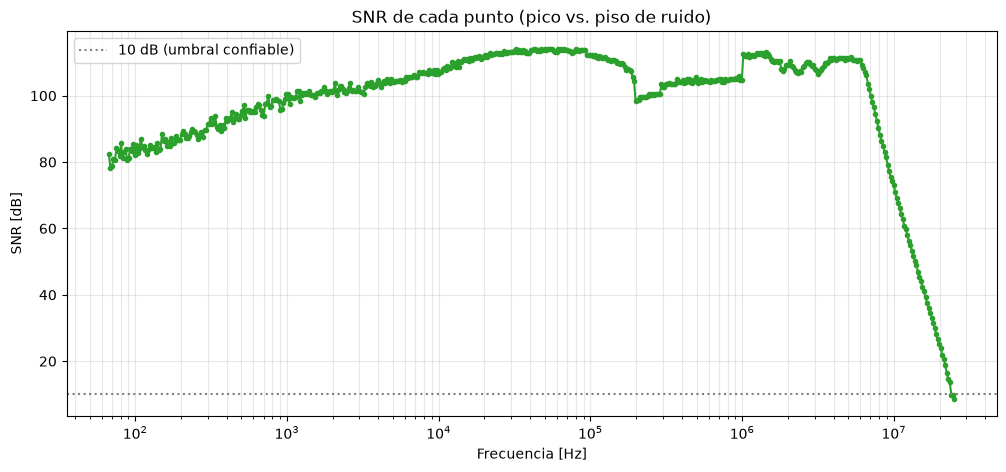

3 puntos con SNR < 10 dB, de 23.9 a 25 MHz -- en esa zona la atenuacion medida (y f_c medida, si cae ahi) no es confiable.


In [8]:
snr_minimo_confiable = 10  # dB

plt.figure(figsize=(12, 5))
plt.plot(resultados_filtro["f_test"], resultados_filtro["snr_db"], "o-", ms=3, color="tab:green")
plt.axhline(snr_minimo_confiable, color="gray", linestyle=":", label=f"{snr_minimo_confiable} dB (umbral confiable)")
plt.xscale("log")
plt.xlabel("Frecuencia [Hz]")
plt.ylabel("SNR [dB]")
plt.title("SNR de cada punto (pico vs. piso de ruido)")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.show()

dudosos = resultados_filtro[resultados_filtro["snr_db"] < snr_minimo_confiable]
if len(dudosos) == 0:
    print("Todos los puntos tienen SNR > umbral -- todo el barrido es confiable.")
else:
    print(f"{len(dudosos)} puntos con SNR < {snr_minimo_confiable} dB, de "
          f"{dudosos['f_test'].min()/1e6:.3g} a {dudosos['f_test'].max()/1e6:.3g} MHz -- "
          "en esa zona la atenuacion medida (y f_c medida, si cae ahi) no es confiable.")

## Ripple en la banda de paso

Que tan plana es la zona antes del corte (misma zona `en_banda_pasante` que
se uso como referencia). Filtros de orden alto a veces tienen un repunte
(peaking) cerca de f_c en vez de quedar perfectamente planos.

In [ ]:
banda_pasante = resultados_filtro[en_banda_pasante]

plt.figure(figsize=(12, 5))
plt.plot(banda_pasante["f_test"], banda_pasante["peak_amp"], "o-", ms=3)
plt.xscale("log")
plt.xlabel("Frecuencia [Hz]")
plt.ylabel("Amplitud del pico [dBm]")
plt.title("Zoom en la banda de paso (antes del corte)")
plt.grid(True, which="both", alpha=0.3)
plt.show()

print(f"Ripple en banda de paso: {banda_pasante['peak_amp'].max() - banda_pasante['peak_amp'].min():.3f} dB "
      f"pico a pico (std={banda_pasante['peak_amp'].std():.3f} dB)")

## Pendiente de caida (orden del filtro)

Que tan rapido cae la senal por encima del corte dice el orden del filtro:
un RC simple (1er orden) cae 20 dB/decada, uno de 2do orden 40 dB/decada,
etc. Se ajusta una recta a la atenuacion (en dB) vs. log10(frecuencia), en
la zona de transicion y solo con los puntos de SNR confiable (si no, el
piso de ruido aplana la curva y arruina el ajuste).

In [ ]:
en_transicion = (
    (resultados_filtro["f_test"] > f_corte_medida)
    & (resultados_filtro["snr_db"] > snr_minimo_confiable)
)
transicion = resultados_filtro[en_transicion]

if len(transicion) < 2:
    print("Muy pocos puntos confiables por encima del corte -- no se puede ajustar la pendiente.")
else:
    pendiente_db_por_decada, ordenada = np.polyfit(
        np.log10(transicion["f_test"]), transicion["atenuacion_db"], 1
    )
    orden_estimado = pendiente_db_por_decada / 20

    plt.figure(figsize=(12, 6))
    plt.plot(resultados_filtro["f_test"], resultados_filtro["atenuacion_db"], "o", ms=3, label="datos")
    f_ajuste = transicion["f_test"]
    plt.plot(f_ajuste, pendiente_db_por_decada * np.log10(f_ajuste) + ordenada,
              "-", color="tab:red", label=f"ajuste: {pendiente_db_por_decada:.1f} dB/decada")
    plt.xscale("log")
    plt.xlabel("Frecuencia [Hz]")
    plt.ylabel("Atenuacion respecto a la banda pasante [dB]")
    plt.title("Pendiente de caida en la zona de transicion")
    plt.grid(True, which="both", alpha=0.3)
    plt.legend()
    plt.show()

    print(f"Pendiente: {pendiente_db_por_decada:.1f} dB/decada")
    print(f"Orden estimado: ~{orden_estimado:.1f} (un RC simple da 20 dB/decada por orden)")